<a href="https://colab.research.google.com/github/ishikadubey1105/HACK-O-WEEK-SEM-V/blob/main/week15_16_deployment_neural_network_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 15 & 16 — Model Deployment Basics & Neural Network from Scratch

**Topics**
1. Model deployment basics — saving/loading models with `pickle` and `joblib`
2. Perceptrons, activation functions, forward & backward propagation
3. Loss functions and optimizers (SGD, Adam)
4. A neural network built from scratch in **NumPy** (forward pass, loss, backprop, weight updates)

**Dataset:** `student_habits_performance.csv` — same dataset used all semester.
**Task:** predict `Pass` / `Fail` (`exam_score >= 60`).

> **Colab note:** upload `student_habits_performance.csv` first. A synthetic
> fallback keeps every cell runnable without it. Only NumPy is used to build
> the network; scikit-learn is used only for scaling, splitting, the
> deployment demo, and as a baseline to compare against.


In [1]:
# Imports
import os
import time
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (7, 5)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Load & Prepare Data

In [2]:
DATA_PATH = "student_habits_performance.csv"

def generate_synthetic_dataset(n=1000):
    study_hours = np.clip(np.random.normal(4.0, 1.8, n), 0, 12)
    sleep_hours = np.clip(np.random.normal(6.8, 1.2, n), 3, 10)
    attendance = np.clip(np.random.normal(85, 10, n), 40, 100)
    social_media = np.clip(np.random.normal(2.5, 1.3, n), 0, 8)
    netflix = np.clip(np.random.normal(1.2, 1.0, n), 0, 6)
    mental_health = np.random.randint(1, 11, n)
    exercise_freq = np.random.poisson(2.5, n).clip(0, 7)
    exam_score = np.clip(
        study_hours * 6.5 + sleep_hours * 2.0 + attendance * 0.25
        - social_media * 3.0 - netflix * 2.0 + mental_health * 1.2
        + np.random.normal(0, 8, n), 0, 100
    ).round(1)
    return pd.DataFrame({
        "study_hours_per_day": study_hours.round(1), "sleep_hours": sleep_hours.round(1),
        "attendance_percentage": attendance.round(1), "social_media_hours": social_media.round(1),
        "netflix_hours": netflix.round(1), "mental_health_rating": mental_health,
        "exercise_frequency": exercise_freq, "exam_score": exam_score,
    })

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded real dataset: {df.shape}")
else:
    print("CSV not found - using synthetic fallback.")
    df = generate_synthetic_dataset(1000)

df = df.drop_duplicates()

features = [c for c in [
    "study_hours_per_day", "social_media_hours", "netflix_hours", "sleep_hours",
    "attendance_percentage", "exercise_frequency", "mental_health_rating",
] if c in df.columns]

df["pass_fail"] = (df["exam_score"] >= 60).astype(int)
X = df[features].fillna(df[features].median())
y = df["pass_fail"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Features:", features)
print("Train / Test:", X_train_s.shape, X_test_s.shape)
print("Pass rate (train):", round(y_train.mean(), 3))


Loaded real dataset: (1000, 16)
Features: ['study_hours_per_day', 'social_media_hours', 'netflix_hours', 'sleep_hours', 'attendance_percentage', 'exercise_frequency', 'mental_health_rating']
Train / Test: (800, 7) (200, 7)
Pass rate (train): 0.72


## Part 1 — Model Deployment Basics: Saving & Loading Models

A trained model only becomes useful when it can be **saved to disk, loaded
somewhere else, and used to predict on new data** — without retraining.

| | `pickle` | `joblib` |
|---|---|---|
| Part of | Python standard library | separate package (installed with scikit-learn) |
| Best for | general Python objects | objects holding **large NumPy arrays** (sklearn models) — faster and more efficient |
| Usage | `pickle.dump(obj, file)` | `joblib.dump(obj, path)` |

> **Security note:** never load a `pickle`/`joblib` file from a source you
> don't trust — unpickling can execute arbitrary code.

Key deployment rule: **save the preprocessing (scaler) together with the
model**, otherwise new data won't be transformed the same way as training
data. A scikit-learn `Pipeline` bundles both into one object.


In [3]:
os.makedirs("models", exist_ok=True)

# Bundle scaler + model into ONE pipeline so they are saved together
deploy_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
deploy_model.fit(X_train, y_train)      # raw (unscaled) features go in; pipeline scales internally
baseline_acc = accuracy_score(y_test, deploy_model.predict(X_test))
print(f"Logistic Regression baseline test accuracy: {baseline_acc:.3f}")


Logistic Regression baseline test accuracy: 0.920


In [4]:
# ---- Save with pickle ----
with open("models/student_model.pkl", "wb") as f:
    pickle.dump(deploy_model, f)

# ---- Save with joblib ----
joblib.dump(deploy_model, "models/student_model.joblib")

for path in ["models/student_model.pkl", "models/student_model.joblib"]:
    print(f"{path:35s} {os.path.getsize(path) / 1024:.1f} KB")


models/student_model.pkl            1.5 KB
models/student_model.joblib         1.9 KB


In [5]:
# ---- Load both back and verify they behave identically to the original ----
with open("models/student_model.pkl", "rb") as f:
    model_from_pickle = pickle.load(f)
model_from_joblib = joblib.load("models/student_model.joblib")

orig_pred = deploy_model.predict(X_test)
print("pickle  predictions identical:", np.array_equal(orig_pred, model_from_pickle.predict(X_test)))
print("joblib  predictions identical:", np.array_equal(orig_pred, model_from_joblib.predict(X_test)))


pickle  predictions identical: True
joblib  predictions identical: True


In [6]:
# ---- A tiny "deployment" function: what a web API endpoint would call ----
def predict_student(sample: dict, model_path="models/student_model.joblib"):
    """Load the saved model and return a prediction for ONE new student."""
    model = joblib.load(model_path)
    row = pd.DataFrame([sample])[features]          # same column order as training
    proba = float(model.predict_proba(row)[0, 1])
    return {"prediction": "Pass" if proba >= 0.5 else "Fail", "pass_probability": round(proba, 3)}

new_student = {
    "study_hours_per_day": 5.5, "social_media_hours": 1.5, "netflix_hours": 0.5,
    "sleep_hours": 7.5, "attendance_percentage": 92, "exercise_frequency": 3,
    "mental_health_rating": 7,
}
predict_student({k: v for k, v in new_student.items() if k in features})


{'prediction': 'Pass', 'pass_probability': 1.0}

In a real deployment, `predict_student` would sit behind an API route
(for example the same Flask pattern from the Week 1 Library API project):
the route receives JSON, calls this function, and returns the JSON result.


## Part 2 — Perceptrons & Activation Functions

### 2.1 The perceptron

A perceptron is the simplest neuron:

$$z = w_1 x_1 + w_2 x_2 + \dots + b \qquad \hat{y} = \text{step}(z)$$

**Learning rule:** for every sample, `w += lr * (y - y_hat) * x` and
`b += lr * (y - y_hat)` — weights only change when the prediction is wrong.

We use just two features so the decision boundary can be drawn.


In [7]:
class Perceptron:
    """Single neuron with a step activation, trained with the perceptron rule."""

    def __init__(self, lr=0.1, epochs=30, seed=42):
        self.lr, self.epochs = lr, epochs
        self.rng = np.random.RandomState(seed)

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.acc_history = []
        for _ in range(self.epochs):
            for i in self.rng.permutation(len(X)):
                error = y[i] - (1 if X[i] @ self.w + self.b >= 0 else 0)
                self.w += self.lr * error * X[i]
                self.b += self.lr * error
            self.acc_history.append(np.mean(self.predict(X) == y))
        return self


two_feats = [features.index("study_hours_per_day"), features.index("social_media_hours")]
Xp_train, Xp_test = X_train_s[:, two_feats], X_test_s[:, two_feats]

perc = Perceptron(lr=0.1, epochs=30).fit(Xp_train, y_train.to_numpy())
print("Perceptron weights:", perc.w.round(3), "bias:", round(perc.b, 3))
print(f"Train acc: {np.mean(perc.predict(Xp_train) == y_train):.3f} | "
      f"Test acc: {np.mean(perc.predict(Xp_test) == y_test):.3f}")


Perceptron weights: [ 0.281 -0.115] bias: 0.3
Train acc: 0.838 | Test acc: 0.835


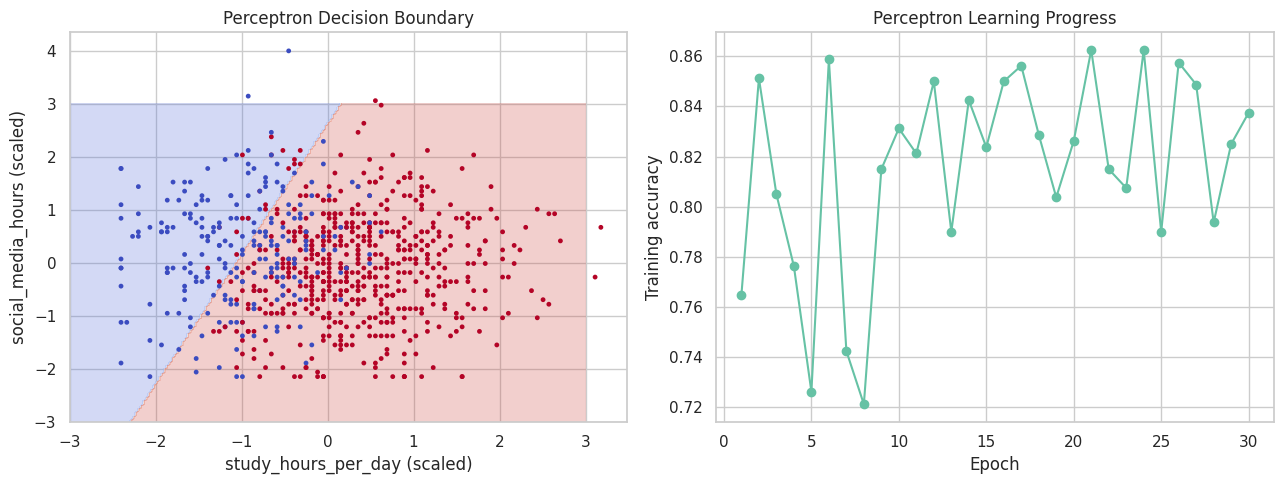

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# decision boundary
xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
zz = perc.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[0].contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
axes[0].scatter(Xp_train[:, 0], Xp_train[:, 1], c=y_train, cmap="coolwarm", s=12, edgecolor="none")
axes[0].set_xlabel("study_hours_per_day (scaled)")
axes[0].set_ylabel("social_media_hours (scaled)")
axes[0].set_title("Perceptron Decision Boundary")

axes[1].plot(range(1, len(perc.acc_history) + 1), perc.acc_history, marker="o")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Training accuracy")
axes[1].set_title("Perceptron Learning Progress")
plt.tight_layout()
plt.show()


**Limitation:** a perceptron can only draw a *straight line* boundary and
its step function has no useful gradient, so it can't be trained by
gradient descent or stacked into deep networks. Both problems are solved by
using a **smooth, differentiable activation function** and stacking layers.

### 2.2 Activation functions

An activation function adds **non-linearity**. Without it, any stack of
layers collapses into a single linear transformation.


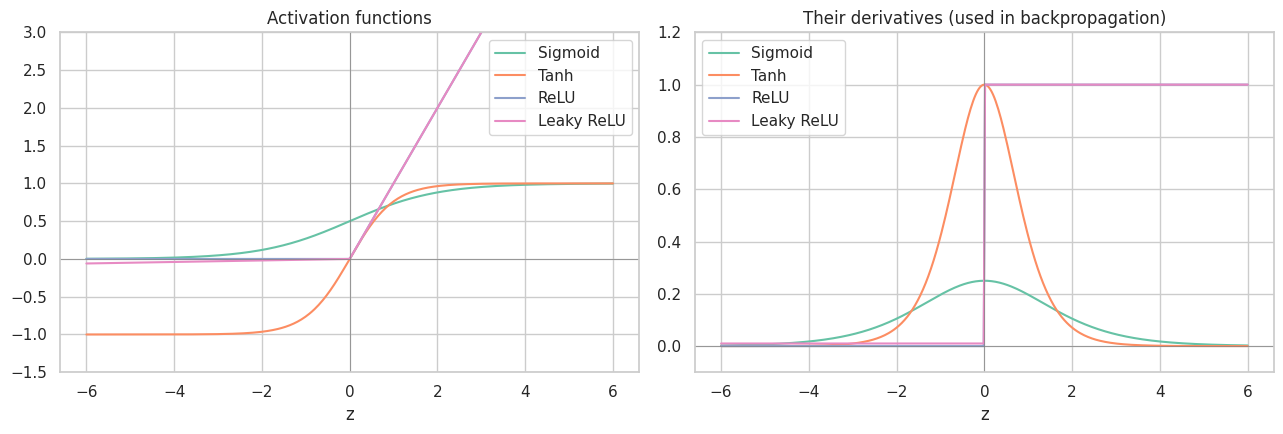

In [9]:
def sigmoid(z):        return 1 / (1 + np.exp(-z))
def sigmoid_d(z):      s = sigmoid(z); return s * (1 - s)
def tanh(z):           return np.tanh(z)
def tanh_d(z):         return 1 - np.tanh(z) ** 2
def relu(z):           return np.maximum(0, z)
def relu_d(z):         return (z > 0).astype(float)
def leaky_relu(z, a=0.01):    return np.where(z > 0, z, a * z)
def leaky_relu_d(z, a=0.01):  return np.where(z > 0, 1.0, a)

activations = {
    "Sigmoid":    (sigmoid, sigmoid_d),
    "Tanh":       (tanh, tanh_d),
    "ReLU":       (relu, relu_d),
    "Leaky ReLU": (leaky_relu, leaky_relu_d),
}

z = np.linspace(-6, 6, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (f, df_) in activations.items():
    axes[0].plot(z, f(z), label=name)
    axes[1].plot(z, df_(z), label=name)
axes[0].set_title("Activation functions"); axes[0].set_ylim(-1.5, 3); axes[0].legend()
axes[1].set_title("Their derivatives (used in backpropagation)"); axes[1].set_ylim(-0.1, 1.2); axes[1].legend()
for ax in axes:
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5); ax.set_xlabel("z")
plt.tight_layout()
plt.show()


| Activation | Range | Where it's used | Watch out for |
|---|---|---|---|
| Sigmoid | (0, 1) | output layer for binary classification | derivative <= 0.25 -> **vanishing gradients** in deep nets |
| Tanh | (-1, 1) | hidden layers (zero-centred) | still saturates at both ends |
| ReLU | [0, inf) | default for hidden layers | "dead" neurons if z stays negative |
| Leaky ReLU | (-inf, inf) | fixes dead ReLU | small extra hyper-parameter |


## Part 3 — Loss Functions & Optimizers

### 3.1 Loss functions

The loss measures **how wrong** the predictions are — it's the single
number training tries to minimize.

- **MSE** (regression): $\frac{1}{m}\sum (y - \hat{y})^2$
- **Binary cross-entropy** (binary classification): $-\frac{1}{m}\sum \big[y\log\hat{y} + (1-y)\log(1-\hat{y})\big]$

Cross-entropy punishes *confident wrong* answers far more heavily than MSE.


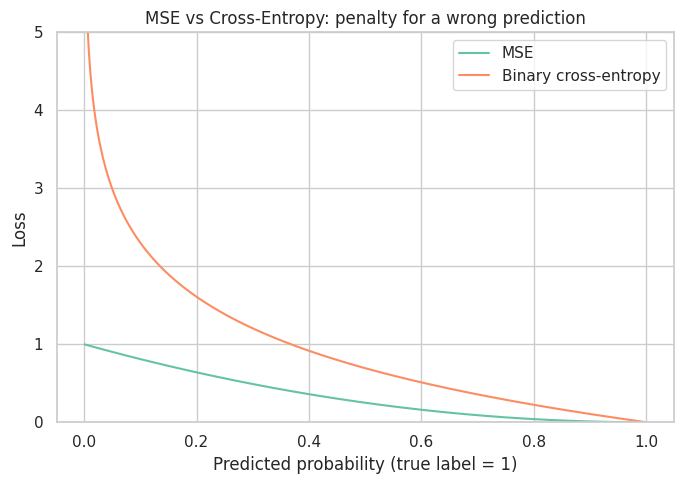

In [10]:
def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def bce_loss(y_true, y_pred, eps=1e-12):
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

# Loss when the TRUE label is 1, as the predicted probability varies
p = np.linspace(0.001, 0.999, 400)
fig, ax = plt.subplots()
ax.plot(p, [mse_loss(1, v) for v in p], label="MSE")
ax.plot(p, [bce_loss(1, v) for v in p], label="Binary cross-entropy")
ax.set_xlabel("Predicted probability (true label = 1)")
ax.set_ylabel("Loss")
ax.set_title("MSE vs Cross-Entropy: penalty for a wrong prediction")
ax.set_ylim(0, 5)
ax.legend()
plt.tight_layout()
plt.show()


### 3.2 Optimizers: SGD and Adam

An optimizer decides **how to use the gradients to update the weights**.

**SGD** (stochastic gradient descent): $\;w \leftarrow w - \eta\, g$

**Adam** keeps a running average of the gradient (momentum, `m`) and of the
squared gradient (scale, `v`), then takes a per-parameter adaptive step:

$$m = \beta_1 m + (1-\beta_1) g \qquad v = \beta_2 v + (1-\beta_2) g^2$$
$$\hat m = \frac{m}{1-\beta_1^t} \quad \hat v = \frac{v}{1-\beta_2^t} \qquad w \leftarrow w - \eta\,\frac{\hat m}{\sqrt{\hat v}+\epsilon}$$

Both are implemented below as small classes working on a **dictionary of
parameters** so they can be reused by the neural network in Part 4.


In [11]:
class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr

    def step(self, params, grads):
        for k in params:
            params[k] -= self.lr * grads[k]


class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m, self.v, self.t = {}, {}, 0

    def step(self, params, grads):
        self.t += 1
        for k in params:
            if k not in self.m:
                self.m[k] = np.zeros_like(params[k])
                self.v[k] = np.zeros_like(params[k])
            self.m[k] = self.beta1 * self.m[k] + (1 - self.beta1) * grads[k]
            self.v[k] = self.beta2 * self.v[k] + (1 - self.beta2) * grads[k] ** 2
            m_hat = self.m[k] / (1 - self.beta1 ** self.t)
            v_hat = self.v[k] / (1 - self.beta2 ** self.t)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


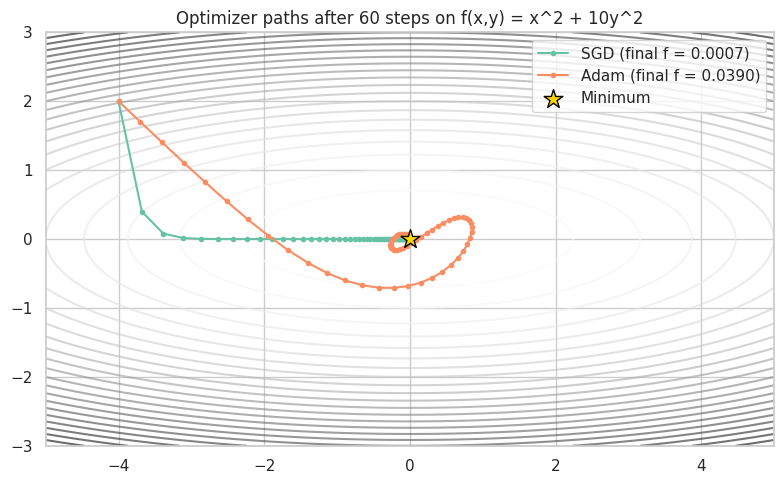

In [12]:
# Compare the optimizers on a simple 2-D "elongated bowl": f(x, y) = x^2 + 10*y^2
def f(p):        return p["x"] ** 2 + 10 * p["y"] ** 2
def grad_f(p):   return {"x": 2 * p["x"], "y": 20 * p["y"]}

def run_optimizer(optimizer, steps=60, start=(-4.0, 2.0)):
    params = {"x": np.array(start[0]), "y": np.array(start[1])}
    path = [(params["x"].item(), params["y"].item())]
    for _ in range(steps):
        optimizer.step(params, grad_f(params))
        path.append((params["x"].item(), params["y"].item()))
    return np.array(path), f(params).item()

sgd_path, sgd_final = run_optimizer(SGD(lr=0.04))
adam_path, adam_final = run_optimizer(Adam(lr=0.3))

gx, gy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-3, 3, 200))
fig, ax = plt.subplots(figsize=(8, 5))
ax.contour(gx, gy, gx ** 2 + 10 * gy ** 2, levels=25, cmap="Greys", alpha=0.6)
ax.plot(*sgd_path.T, marker=".", label=f"SGD (final f = {sgd_final:.4f})")
ax.plot(*adam_path.T, marker=".", label=f"Adam (final f = {adam_final:.4f})")
ax.scatter([0], [0], marker="*", s=200, color="gold", edgecolor="k", zorder=5, label="Minimum")
ax.set_title("Optimizer paths after 60 steps on f(x,y) = x^2 + 10y^2")
ax.legend()
plt.tight_layout()
plt.show()


## Part 4 — Neural Network from Scratch (NumPy)

Architecture for our Pass/Fail problem: **7 inputs -> 16 hidden (ReLU) -> 8 hidden (ReLU) -> 1 output (sigmoid)**.

### The four steps of every training iteration

1. **Forward propagation** — push inputs through each layer: $Z = AW + b,\; A = g(Z)$
2. **Loss calculation** — binary cross-entropy between $\hat y$ and $y$
3. **Backpropagation** — apply the **chain rule** from the output back to the input to get $\partial L / \partial W$ and $\partial L / \partial b$ for every layer
4. **Weight update** — the optimizer (SGD / Adam) moves each parameter against its gradient

**Backprop equations** (sigmoid output + cross-entropy gives a neat simplification):

- Output layer: $\;dZ_L = (A_L - y)/m$
- Any layer: $\;dW_l = A_{l-1}^T\, dZ_l \qquad db_l = \sum dZ_l$
- Pass backwards: $\;dZ_{l-1} = (dZ_l\, W_l^T) \odot g'(Z_{l-1})$


In [13]:
class NeuralNetwork:
    """Fully-connected network: ReLU hidden layers + sigmoid output, binary cross-entropy loss."""

    def __init__(self, layer_sizes, seed=42):
        self.layer_sizes = layer_sizes
        self.L = len(layer_sizes) - 1                    # number of weight layers
        rng = np.random.RandomState(seed)
        self.params = {}
        for l in range(1, self.L + 1):
            fan_in = layer_sizes[l - 1]
            # He initialisation - suited to ReLU layers
            self.params[f"W{l}"] = rng.randn(fan_in, layer_sizes[l]) * np.sqrt(2.0 / fan_in)
            self.params[f"b{l}"] = np.zeros((1, layer_sizes[l]))

    # ---------- 1. forward propagation ----------
    def forward(self, X):
        self.cache = {"A0": X}
        A = X
        for l in range(1, self.L + 1):
            Z = A @ self.params[f"W{l}"] + self.params[f"b{l}"]
            A = sigmoid(Z) if l == self.L else relu(Z)
            self.cache[f"Z{l}"], self.cache[f"A{l}"] = Z, A
        return A

    # ---------- 2. loss ----------
    def compute_loss(self, y_true, y_pred):
        return bce_loss(y_true, y_pred)

    # ---------- 3. backpropagation ----------
    def backward(self, y_true):
        m = y_true.shape[0]
        grads = {}
        dZ = (self.cache[f"A{self.L}"] - y_true) / m     # sigmoid + BCE shortcut
        for l in range(self.L, 0, -1):
            grads[f"W{l}"] = self.cache[f"A{l-1}"].T @ dZ
            grads[f"b{l}"] = dZ.sum(axis=0, keepdims=True)
            if l > 1:
                dA_prev = dZ @ self.params[f"W{l}"].T
                dZ = dA_prev * relu_d(self.cache[f"Z{l-1}"])
        return grads

    # ---------- 4. training loop (includes the weight update) ----------
    def fit(self, X, y, optimizer, epochs=200, batch_size=32, X_val=None, y_val=None, seed=0, verbose=True):
        y = y.reshape(-1, 1)
        rng = np.random.RandomState(seed)
        history = {"loss": [], "train_acc": [], "val_acc": []}
        for epoch in range(1, epochs + 1):
            order = rng.permutation(len(X))
            for start in range(0, len(X), batch_size):
                idx = order[start:start + batch_size]
                self.forward(X[idx])                      # forward
                grads = self.backward(y[idx])             # backward
                optimizer.step(self.params, grads)        # update weights

            full_pred = self.forward(X)
            history["loss"].append(self.compute_loss(y, full_pred))
            history["train_acc"].append(np.mean((full_pred >= 0.5) == y))
            if X_val is not None:
                history["val_acc"].append(np.mean(self.predict(X_val) == y_val.reshape(-1, 1)))
            if verbose and epoch % 50 == 0:
                print(f"epoch {epoch:4d} | loss {history['loss'][-1]:.4f} | train acc {history['train_acc'][-1]:.3f}")
        return history

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X):
        return (self.forward(X) >= 0.5).astype(int)


### 4.1 Gradient check — proving backprop is correct

Backprop is easy to get subtly wrong. The standard test: compare our
analytic gradients against **numerical gradients**
$\;\frac{L(w+\epsilon) - L(w-\epsilon)}{2\epsilon}$. They should agree to
many decimal places.


In [14]:
def gradient_check(n_checks_per_param=5, eps=1e-5):
    net = NeuralNetwork([len(features), 6, 4, 1], seed=1)
    Xs, ys = X_train_s[:20], y_train.to_numpy()[:20].reshape(-1, 1)

    net.forward(Xs)
    analytic = net.backward(ys)

    max_rel_err = 0
    rng = np.random.RandomState(0)
    for key, param in net.params.items():
        for _ in range(n_checks_per_param):
            idx = tuple(rng.randint(0, s) for s in param.shape)
            original = param[idx]

            param[idx] = original + eps
            loss_plus = net.compute_loss(ys, net.forward(Xs))
            param[idx] = original - eps
            loss_minus = net.compute_loss(ys, net.forward(Xs))
            param[idx] = original

            numeric = (loss_plus - loss_minus) / (2 * eps)
            a = analytic[key][idx]
            rel_err = abs(a - numeric) / max(1e-8, abs(a) + abs(numeric))
            max_rel_err = max(max_rel_err, rel_err)
    return max_rel_err

err = gradient_check()
print(f"Max relative error between analytic and numerical gradients: {err:.2e}")
print("Gradient check PASSED" if err < 1e-4 else "Gradient check FAILED - backprop has a bug")


Max relative error between analytic and numerical gradients: 7.32e-10
Gradient check PASSED


### 4.2 Train with SGD vs Adam

Same architecture, same initial weights, same data — only the optimizer differs.


In [15]:
y_train_np, y_test_np = y_train.to_numpy(), y_test.to_numpy()
arch = [len(features), 16, 8, 1]

net_sgd = NeuralNetwork(arch, seed=42)
t0 = time.time()
hist_sgd = net_sgd.fit(X_train_s, y_train_np, SGD(lr=0.05), epochs=200, batch_size=32,
                        X_val=X_test_s, y_val=y_test_np)
print(f"SGD finished in {time.time() - t0:.1f}s\n")

net_adam = NeuralNetwork(arch, seed=42)
t0 = time.time()
hist_adam = net_adam.fit(X_train_s, y_train_np, Adam(lr=0.005), epochs=200, batch_size=32,
                          X_val=X_test_s, y_val=y_test_np)
print(f"Adam finished in {time.time() - t0:.1f}s")


epoch   50 | loss 0.1440 | train acc 0.940
epoch  100 | loss 0.1233 | train acc 0.949
epoch  150 | loss 0.1089 | train acc 0.963
epoch  200 | loss 0.0957 | train acc 0.965
SGD finished in 0.6s

epoch   50 | loss 0.0990 | train acc 0.971
epoch  100 | loss 0.0548 | train acc 0.986
epoch  150 | loss 0.0356 | train acc 0.991
epoch  200 | loss 0.0186 | train acc 0.999
Adam finished in 1.1s


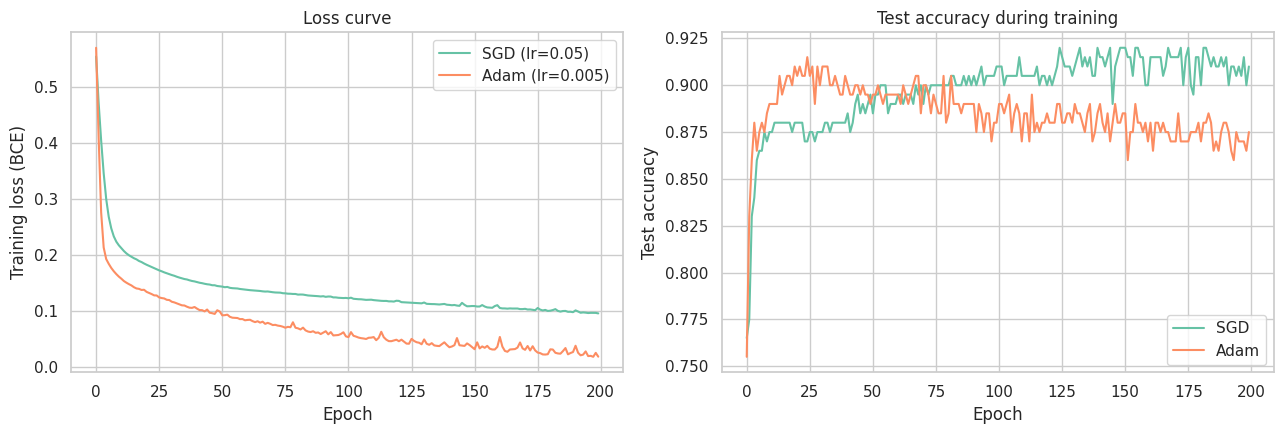

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist_sgd["loss"], label="SGD (lr=0.05)")
axes[0].plot(hist_adam["loss"], label="Adam (lr=0.005)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Training loss (BCE)")
axes[0].set_title("Loss curve"); axes[0].legend()

axes[1].plot(hist_sgd["val_acc"], label="SGD")
axes[1].plot(hist_adam["val_acc"], label="Adam")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Test accuracy")
axes[1].set_title("Test accuracy during training"); axes[1].legend()
plt.tight_layout()
plt.show()


### 4.3 Evaluate the from-scratch network

In [17]:
results = {}
for name, net in [("SGD", net_sgd), ("Adam", net_adam)]:
    results[name] = accuracy_score(y_test_np, net.predict(X_test_s).ravel())
results["Logistic Regression (sklearn baseline)"] = baseline_acc

pd.Series(results, name="test_accuracy").round(3).to_frame()


,test_accuracy
SGD,0.910
Adam,0.875
Logistic Regression (sklearn baseline),0.920


              precision    recall  f1-score   support

        Fail       0.78      0.77      0.77        56
        Pass       0.91      0.92      0.91       144

    accuracy                           0.88       200
   macro avg       0.85      0.84      0.84       200
weighted avg       0.87      0.88      0.87       200



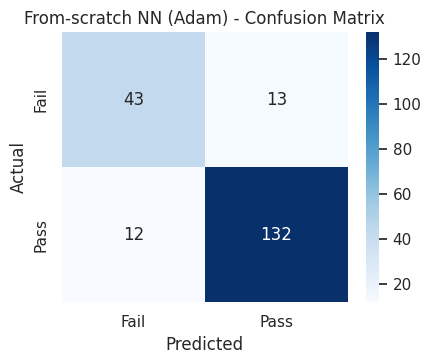

In [18]:
y_pred_adam = net_adam.predict(X_test_s).ravel()
print(classification_report(y_test_np, y_pred_adam, target_names=["Fail", "Pass"]))

cm = confusion_matrix(y_test_np, y_pred_adam)
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("From-scratch NN (Adam) - Confusion Matrix")
plt.tight_layout()
plt.show()


## Part 5 — Deploying the From-Scratch Network

Combining Part 1 and Part 4: save the trained weights **together with the
scaler and feature list**, then reload them in a fresh object and confirm
the predictions are identical.


In [19]:
artifact = {
    "layer_sizes": arch,
    "params": net_adam.params,
    "scaler": scaler,
    "features": features,
}
joblib.dump(artifact, "models/student_nn_scratch.joblib")
print(f"Saved: models/student_nn_scratch.joblib ({os.path.getsize('models/student_nn_scratch.joblib') / 1024:.1f} KB)")

# ---- Reload into a brand-new network ----
loaded = joblib.load("models/student_nn_scratch.joblib")
restored_net = NeuralNetwork(loaded["layer_sizes"])
restored_net.params = loaded["params"]

same = np.array_equal(net_adam.predict(X_test_s), restored_net.predict(X_test_s))
print("Restored network gives identical predictions:", same)


Saved: models/student_nn_scratch.joblib (3.8 KB)
Restored network gives identical predictions: True


In [20]:
def predict_with_scratch_nn(sample: dict, path="models/student_nn_scratch.joblib"):
    """Deployment-style helper: load artifact, scale the raw input, run forward pass."""
    art = joblib.load(path)
    net = NeuralNetwork(art["layer_sizes"])
    net.params = art["params"]
    row = pd.DataFrame([sample])[art["features"]]
    proba = float(net.predict_proba(art["scaler"].transform(row))[0, 0])
    return {"prediction": "Pass" if proba >= 0.5 else "Fail", "pass_probability": round(proba, 3)}

predict_with_scratch_nn({k: v for k, v in new_student.items() if k in features})


{'prediction': 'Pass', 'pass_probability': 1.0}

## Summary

In [21]:
print("Week 15 & 16 summary")
print("-" * 55)
print(f"Features used                    : {len(features)}")
print(f"Network architecture             : {arch}")
print(f"Gradient check max rel. error    : {err:.2e}")
print(f"Perceptron test accuracy (2 feat): {np.mean(perc.predict(Xp_test) == y_test):.3f}")
print(f"NN from scratch - SGD            : {results['SGD']:.3f}")
print(f"NN from scratch - Adam           : {results['Adam']:.3f}")
print(f"Sklearn Logistic Regression      : {baseline_acc:.3f}")
print(f"Final training loss  SGD / Adam  : {hist_sgd['loss'][-1]:.4f} / {hist_adam['loss'][-1]:.4f}")
print("Saved models:", sorted(os.listdir("models")))


Week 15 & 16 summary
-------------------------------------------------------
Features used                    : 7
Network architecture             : [7, 16, 8, 1]
Gradient check max rel. error    : 7.32e-10
Perceptron test accuracy (2 feat): 0.835
NN from scratch - SGD            : 0.910
NN from scratch - Adam           : 0.875
Sklearn Logistic Regression      : 0.920
Final training loss  SGD / Adam  : 0.0957 / 0.0186
Saved models: ['student_model.joblib', 'student_model.pkl', 'student_nn_scratch.joblib']
